# 02. Optimizers, schedules and other training choices (XLM-R base)

With the data fixed by `01_data_mix` (`ner/recipes.py`), we change one thing at a time against the
baseline: two stages (2 epochs on the Kaggle sentences, then 2 epochs on the synthetic posts), AdamW,
lr 3e-5 in stage 1 and 2e-5 in stage 2, linear decay with 10% warmup in each stage, weight decay 0.01,
batch 32, 256-token windows, all sub-tokens labeled. Optimizer, schedule and the other settings apply to
both stages. A changed learning rate is scaled in both stages, so stage 2 always runs at 2/3 of stage 1.
Every run uses validation fold 0, so the scores are comparable with each other and with notebook 01.

| Group | What changes | Why it might matter |
| --- | --- | --- |
| learning rate | 1e-5, 5e-5, 1e-4 | too low underfits in 2+2 epochs; too high can wreck the pre-trained weights |
| schedule | cosine, constant after warmup, no warmup | how fast the step size shrinks; warmup protects the pre-trained weights from the random head's first large gradients |
| optimizer | Adafactor, SGD with momentum | Adafactor keeps factored second moments (less memory); SGD has no per-parameter scaling, and is known to fine-tune transformers poorly |
| layer-wise lr decay | 0.9 per layer | lower layers hold general language knowledge and should change less |
| regularization | label smoothing 0.1, frozen embeddings | the labels are noisy (pseudo-labels, LLM labels, annotator style); frozen embeddings keep rare place names' pre-trained vectors |
| labels | first sub-token only | the original BERT NER recipe; fewer training targets, but no conflicting targets inside a word |
| shape | 128-token windows, batch 16, 4 epochs in stage 2 | shorter context, more steps; in 01 `half_B` was still rising at the end of stage 2 |

For the report: loss and F1 curves of each group below, gradient-flow heatmaps for the most different
optimizers, and all runs in W&B (project `dl-a4-ner`, tag `02_optimization`).

### Setup

On Colab (T4 or better): clones the repo, installs W&B and keeps every run on Drive in
`dl-a4-ner/runs`, so a disconnect loses at most the run in progress (finished runs are loaded, not
retrained). Teammates: put a shortcut to the shared `dl-a4-ner` folder in your My Drive, so all runs
land in one place. Set `WANDB_ENTITY` to the team's W&B entity to log into one shared project.
Locally the notebook runs from the repo root and writes to `transformers/runs`. To check the whole
notebook in a few minutes before using GPU time, set the environment variable `NER_SMOKE=1`: every run
shrinks to a few hundred texts and goes to `transformers/runs_smoke`.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/koalla05/deep-learning-assignment4.git"
WANDB_PROJECT = "dl-a4-ner"  # None switches W&B off
WANDB_ENTITY = None  # the team's W&B entity, so all teammates log into one project

if "google.colab" in sys.modules:
    repo = Path("/content/deep-learning-assignment4")
    if not repo.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(repo)], check=True)
    else:
        subprocess.run(["git", "-C", str(repo), "pull", "-q"], check=True)
    os.chdir(repo)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "wandb"], check=True)
    from google.colab import drive

    drive.mount("/content/drive")
    OUT = Path("/content/drive/MyDrive/dl-a4-ner/runs")
else:
    if Path.cwd().name == "transformers":
        os.chdir("..")
    OUT = Path("transformers/runs")
sys.path.insert(0, os.getcwd())
if os.environ.get("NER_SMOKE"):  # quick end-to-end check with tiny runs, see ner.train.smoke
    OUT, WANDB_PROJECT = Path("transformers/runs_smoke"), None
OUT.mkdir(parents=True, exist_ok=True)
if WANDB_ENTITY:
    os.environ["WANDB_ENTITY"] = WANDB_ENTITY
if WANDB_PROJECT:
    import wandb

    wandb.login()

Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: kov-koalla (kov-koalla-kyiv-school-of-economics) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [2]:
import dataclasses

from ner import plots, recipes
from ner.train import RunConfig, load_run, run_or_load

BASE = RunConfig(
    name="base", model="FacebookAI/xlm-roberta-base", fold=0, data=recipes.DATA,
    **(recipes.STAGE2 or {}), **recipes.OPTIMIZATION, tags=("02_optimization",),
)
print(BASE)


def train(name, **changes):
    if "learning_rate" in changes and BASE.stage2_lr:  # keep the stage-2 lr at the same ratio to stage 1
        changes.setdefault("stage2_lr", changes["learning_rate"] * BASE.stage2_lr / BASE.learning_rate)
    cfg = dataclasses.replace(BASE, name=f"02-{name}", **changes)
    return run_or_load(cfg, OUT, WANDB_PROJECT)

RunConfig(name='base', model='FacebookAI/xlm-roberta-base', data=DataSpec(sentences=None, synthetic='none', synthetic_repeat=1, weight_by_test_like=False), stage2_data=DataSpec(sentences=0, synthetic='all', synthetic_repeat=1, weight_by_test_like=False), stage2_epochs=2, stage2_lr=2e-05, fold=0, optimizer='adamw', learning_rate=3e-05, scheduler='linear', warmup_ratio=0.1, weight_decay=0.01, layer_lr_decay=1.0, epochs=2, batch_size=32, grad_accumulation=1, max_grad_norm=1.0, label_smoothing=0.0, freeze_embeddings=False, max_length=256, stride=64, label_all_subtokens=True, precision='auto', seed=42, eval_sentences_per_epoch=3000, final_eval_sentences=None, grad_flow_every=50, tags=('02_optimization',))


## Baseline

The same settings as the winning run of notebook 01 (`01-two-stage`), trained again under this
notebook's name, so every comparison below differs from it in exactly one setting. With the same seed it
should land close to 01's scores; the difference shows how reproducible a run is on the GPU.

In [3]:
train("baseline")

wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

... (5 outputs left out)

stage 2: sentences=0, synthetic=all -> 3,942 texts, 4,181 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.015827,No log,0.015886,0.012577
2,0.011122,No log,0.016077,0.009732


eval/cv_f1,▃█▁▃
eval/gold26_f1,▁▃▄█
eval/half_B_f1,▁▂▅█
eval/sentences_loss,▅▁██
eval/sentences_runtime,██▁▂
eval/sentences_samples_per_second,▁▁█▇
eval/sentences_steps_per_second,▁▁█▇
eval/synthetic_f1,▁▁▇█
eval/synthetic_loss,██▂▁
eval/synthetic_runtime,▄▁█▂
+36,...


{'cv': {'f1': 0.89288644, 'precision': 0.8842, 'recall': 0.9018},
 'synthetic': {'f1': 0.94677237, 'precision': 0.9379, 'recall': 0.9558},
 'half_B': {'f1': 0.85802469, 'precision': 0.8323, 'recall': 0.8854},
 'half_A': {'f1': 0.88672351, 'precision': 0.8687, 'recall': 0.9055},
 'gold26': {'f1': 0.83783784, 'precision': 0.7381, 'recall': 0.9688},
 'train_minutes': 23.9}

## Learning rate

In [4]:
train("lr1e-5", learning_rate=1e-5)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.bias             | MISSING    | 
classifier.weight           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


stage 1: sentences=all, synthetic=none -> 42,259 texts, 42,259 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.013220,No log,0.014399,0.045345
2,0.008990,No log,0.013325,0.045681


stage 2: sentences=0, synthetic=all -> 3,942 texts, 4,181 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.016934,No log,0.016662,0.013502
2,0.012541,No log,0.015995,0.011623


eval/cv_f1,▆█▁▄
eval/gold26_f1,▁▂▆█
eval/half_B_f1,▁▃▅█
eval/sentences_loss,▃▁█▇
eval/sentences_runtime,▆▃█▁
eval/sentences_samples_per_second,▃▆▁█
eval/sentences_steps_per_second,▃▆▁█
eval/synthetic_f1,▁▁▇█
eval/synthetic_loss,██▁▁
eval/synthetic_runtime,▁▂█▁
+36,...


{'cv': {'f1': 0.88936891, 'precision': 0.8775, 'recall': 0.9015},
 'synthetic': {'f1': 0.9365525, 'precision': 0.9202, 'recall': 0.9535},
 'half_B': {'f1': 0.83920368, 'precision': 0.8083, 'recall': 0.8726},
 'half_A': {'f1': 0.8746988, 'precision': 0.8481, 'recall': 0.903},
 'gold26': {'f1': 0.78481013, 'precision': 0.6596, 'recall': 0.9688},
 'train_minutes': 24.0}

In [5]:
train("lr5e-5", learning_rate=5e-5)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.bias             | MISSING    | 
classifier.weight           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


stage 1: sentences=all, synthetic=none -> 42,259 texts, 42,259 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.015203,No log,0.017326,0.045177
2,0.006852,No log,0.011924,0.038614


stage 2: sentences=0, synthetic=all -> 3,942 texts, 4,181 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.014307,No log,0.021097,0.012805
2,0.010376,No log,0.018204,0.009965


eval/cv_f1,▃█▁▄
eval/gold26_f1,▁▂▅█
eval/half_B_f1,▁▄▆█
eval/sentences_loss,▅▁█▆
eval/sentences_runtime,▃▄█▁
eval/sentences_samples_per_second,▆▅▁█
eval/sentences_steps_per_second,▆▅▁█
eval/synthetic_f1,▁▃██
eval/synthetic_loss,█▇▂▁
eval/synthetic_runtime,▄▄▁█
+36,...


{'cv': {'f1': 0.88765034, 'precision': 0.8801, 'recall': 0.8954},
 'synthetic': {'f1': 0.94213007, 'precision': 0.9321, 'recall': 0.9524},
 'half_B': {'f1': 0.85625, 'precision': 0.8405, 'recall': 0.8726},
 'half_A': {'f1': 0.88480392, 'precision': 0.872, 'recall': 0.898},
 'gold26': {'f1': 0.81081081, 'precision': 0.7143, 'recall': 0.9375},
 'train_minutes': 24.0}

In [6]:
train("lr1e-4", learning_rate=1e-4)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.bias             | MISSING    | 
classifier.weight           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


stage 1: sentences=all, synthetic=none -> 42,259 texts, 42,259 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.014564,No log,0.016860,0.049060
2,0.006194,No log,0.012291,0.042179


stage 2: sentences=0, synthetic=all -> 3,942 texts, 4,181 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.015950,No log,0.022803,0.013392
2,0.010117,No log,0.020175,0.010430


eval/cv_f1,▄█▁▃
eval/gold26_f1,▁▂▆█
eval/half_B_f1,▁▄▅█
eval/sentences_loss,▄▁█▆
eval/sentences_runtime,▄▃█▁
eval/sentences_samples_per_second,▅▆▁█
eval/sentences_steps_per_second,▅▆▁█
eval/synthetic_f1,▁▄▇█
eval/synthetic_loss,█▇▂▁
eval/synthetic_runtime,▅█▁▁
+36,...


{'cv': {'f1': 0.88011645, 'precision': 0.8661, 'recall': 0.8945},
 'synthetic': {'f1': 0.94683065, 'precision': 0.9402, 'recall': 0.9535},
 'half_B': {'f1': 0.85060976, 'precision': 0.8158, 'recall': 0.8885},
 'half_A': {'f1': 0.85575758, 'precision': 0.8345, 'recall': 0.8781},
 'gold26': {'f1': 0.78947368, 'precision': 0.6818, 'recall': 0.9375},
 'train_minutes': 24.0}

## Schedule

In [7]:
train("cosine", scheduler="cosine")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.bias             | MISSING    | 
classifier.weight           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


stage 1: sentences=all, synthetic=none -> 42,259 texts, 42,259 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.013105,No log,0.012972,0.042352
2,0.005725,No log,0.011844,0.047154


stage 2: sentences=0, synthetic=all -> 3,942 texts, 4,181 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.017008,No log,0.017026,0.012256
2,0.010506,No log,0.016682,0.009922


eval/cv_f1,▇█▁▃
eval/gold26_f1,▁▂▄█
eval/half_B_f1,▁▄▅█
eval/sentences_loss,▃▁██
eval/sentences_runtime,▁▆▃█
eval/sentences_samples_per_second,█▃▆▁
eval/sentences_steps_per_second,█▃▆▁
eval/synthetic_f1,▁▁▇█
eval/synthetic_loss,▇█▁▁
eval/synthetic_runtime,█▂▁▆
+36,...


{'cv': {'f1': 0.89375916, 'precision': 0.8851, 'recall': 0.9026},
 'synthetic': {'f1': 0.94465361, 'precision': 0.9334, 'recall': 0.9562},
 'half_B': {'f1': 0.87384615, 'precision': 0.8452, 'recall': 0.9045},
 'half_A': {'f1': 0.87198068, 'precision': 0.8474, 'recall': 0.898},
 'gold26': {'f1': 0.87671233, 'precision': 0.7805, 'recall': 1.0},
 'train_minutes': 24.0}

In [8]:
train("constant", scheduler="constant_with_warmup")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.bias             | MISSING    | 
classifier.weight           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


stage 1: sentences=all, synthetic=none -> 42,259 texts, 42,259 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.016541,No log,0.018301,0.045987
2,0.007335,No log,0.014163,0.045189


stage 2: sentences=0, synthetic=all -> 3,942 texts, 4,181 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.015362,No log,0.018704,0.013765
2,0.010827,No log,0.017495,0.011837


eval/cv_f1,▁█▁▃
eval/gold26_f1,▁▃▅█
eval/half_B_f1,▁▄▆█
eval/sentences_loss,▇▁█▆
eval/sentences_runtime,▅▁█▁
eval/sentences_samples_per_second,▄█▁█
eval/sentences_steps_per_second,▄█▁█
eval/synthetic_f1,▁▂██
eval/synthetic_loss,██▁▁
eval/synthetic_runtime,▂█▇▁
+36,...


{'cv': {'f1': 0.88546332, 'precision': 0.8706, 'recall': 0.9008},
 'synthetic': {'f1': 0.93841532, 'precision': 0.9249, 'recall': 0.9524},
 'half_B': {'f1': 0.84580153, 'precision': 0.8123, 'recall': 0.8822},
 'half_A': {'f1': 0.88512696, 'precision': 0.8612, 'recall': 0.9104},
 'gold26': {'f1': 0.81578947, 'precision': 0.7045, 'recall': 0.9688},
 'train_minutes': 24.0}

In [9]:
train("no-warmup", warmup_ratio=0.0)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.bias             | MISSING    | 
classifier.weight           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


stage 1: sentences=all, synthetic=none -> 42,259 texts, 42,259 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.013953,No log,0.013123,0.040677
2,0.006184,No log,0.011672,0.042505


stage 2: sentences=0, synthetic=all -> 3,942 texts, 4,181 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.015879,No log,0.015279,0.011224
2,0.010707,No log,0.016841,0.010162


eval/cv_f1,▂█▁▄
eval/gold26_f1,▁▁██
eval/half_B_f1,▁▁▄█
eval/sentences_loss,▃▁▆█
eval/sentences_runtime,▄▄█▁
eval/sentences_samples_per_second,▅▅▁█
eval/sentences_steps_per_second,▅▅▁█
eval/synthetic_f1,▁▁▇█
eval/synthetic_loss,██▁▁
eval/synthetic_runtime,▃▂▁█
+36,...


{'cv': {'f1': 0.89689324, 'precision': 0.8935, 'recall': 0.9003},
 'synthetic': {'f1': 0.94548198, 'precision': 0.9361, 'recall': 0.955},
 'half_B': {'f1': 0.86956522, 'precision': 0.8485, 'recall': 0.8917},
 'half_A': {'f1': 0.8809816, 'precision': 0.8692, 'recall': 0.893},
 'gold26': {'f1': 0.81578947, 'precision': 0.7045, 'recall': 0.9688},
 'train_minutes': 24.0}

## Optimizer

Each optimizer gets the learning rate it usually needs: Adafactor without relative steps behaves like
Adam with a slightly larger lr; SGD needs a much larger one because it doesn't divide by the gradient's
running scale.

In [10]:
train("adafactor", optimizer="adafactor", learning_rate=5e-5)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.bias             | MISSING    | 
classifier.weight           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


stage 1: sentences=all, synthetic=none -> 42,259 texts, 42,259 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.012898,No log,0.017343,0.052722
2,0.005200,No log,0.011869,0.049165


stage 2: sentences=0, synthetic=all -> 3,942 texts, 4,181 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.015217,No log,0.015397,0.011731
2,0.009861,No log,0.015805,0.009259


eval/cv_f1,▁█▄▃
eval/gold26_f1,▁▁▃█
eval/half_B_f1,▁▂▅█
eval/sentences_loss,█▁▆▆
eval/sentences_runtime,▃▁█▄
eval/sentences_samples_per_second,▆█▁▅
eval/sentences_steps_per_second,▆█▁▅
eval/synthetic_f1,▁▂██
eval/synthetic_loss,█▇▁▁
eval/synthetic_runtime,▁▃█▇
+36,...


{'cv': {'f1': 0.89543099, 'precision': 0.8909, 'recall': 0.9},
 'synthetic': {'f1': 0.94790487, 'precision': 0.939, 'recall': 0.9569},
 'half_B': {'f1': 0.88087774, 'precision': 0.8673, 'recall': 0.8949},
 'half_A': {'f1': 0.8804878, 'precision': 0.8636, 'recall': 0.898},
 'gold26': {'f1': 0.81081081, 'precision': 0.7143, 'recall': 0.9375},
 'train_minutes': 25.2}

In [11]:
train("sgd", optimizer="sgd", learning_rate=5e-3)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.bias             | MISSING    | 
classifier.weight           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


stage 1: sentences=all, synthetic=none -> 42,259 texts, 42,259 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.023393,No log,0.026194,0.127181
2,0.028988,No log,0.032449,0.149584


stage 2: sentences=0, synthetic=all -> 3,942 texts, 4,181 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.077117,No log,0.123967,0.066271
2,0.057871,No log,0.090825,0.046974


eval/cv_f1,█▆▁▂
eval/gold26_f1,█▄▁█
eval/half_B_f1,█▄▁▁
eval/sentences_loss,▁▁█▆
eval/sentences_runtime,▅▁█▁
eval/sentences_samples_per_second,▄█▁█
eval/sentences_steps_per_second,▄█▁█
eval/synthetic_f1,▅▁▇█
eval/synthetic_loss,▆█▂▁
eval/synthetic_runtime,▄▁█▆
+36,...


{'cv': {'f1': 0.49078441, 'precision': 0.369, 'recall': 0.7327},
 'synthetic': {'f1': 0.62514929, 'precision': 0.566, 'recall': 0.6982},
 'half_B': {'f1': 0.38591917, 'precision': 0.3267, 'recall': 0.4713},
 'half_A': {'f1': 0.40634921, 'precision': 0.3536, 'recall': 0.4776},
 'gold26': {'f1': 0.46464646, 'precision': 0.3433, 'recall': 0.7188},
 'train_minutes': 22.6}

## Layer-wise learning-rate decay

Each layer gets 0.9 times the learning rate of the layer above it: the head 5e-5, the top layer 4.5e-5,
the bottom layer about 1.4e-5 and the embeddings about 1.3e-5.

In [12]:
train("llrd0.9", layer_lr_decay=0.9, learning_rate=5e-5)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.bias             | MISSING    | 
classifier.weight           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


stage 1: sentences=all, synthetic=none -> 42,259 texts, 42,259 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.013575,No log,0.013397,0.039948
2,0.005722,No log,0.011233,0.043410


stage 2: sentences=0, synthetic=all -> 3,942 texts, 4,181 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.014952,No log,0.019093,0.012977
2,0.010615,No log,0.016668,0.009928


eval/cv_f1,▄█▁▃
eval/gold26_f1,▁▂▅█
eval/half_B_f1,▁▃▅█
eval/sentences_loss,▃▁█▆
eval/sentences_runtime,█▃▂▁
eval/sentences_samples_per_second,▁▆▇█
eval/sentences_steps_per_second,▁▆▇█
eval/synthetic_f1,▂▁▇█
eval/synthetic_loss,▇█▂▁
eval/synthetic_runtime,▅█▁▆
+36,...


{'cv': {'f1': 0.88514725, 'precision': 0.8659, 'recall': 0.9053},
 'synthetic': {'f1': 0.94505081, 'precision': 0.9335, 'recall': 0.9569},
 'half_B': {'f1': 0.86645963, 'precision': 0.8455, 'recall': 0.8885},
 'half_A': {'f1': 0.88672351, 'precision': 0.8687, 'recall': 0.9055},
 'gold26': {'f1': 0.87671233, 'precision': 0.7805, 'recall': 1.0},
 'train_minutes': 24.0}

## Regularization and labels

In [13]:
train("smooth0.1", label_smoothing=0.1)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.bias             | MISSING    | 
classifier.weight           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


stage 1: sentences=all, synthetic=none -> 42,259 texts, 42,259 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.300516,No log,0.300819,0.320553
2,0.295618,No log,0.298779,0.319180


stage 2: sentences=0, synthetic=all -> 3,942 texts, 4,181 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.301076,No log,0.307194,0.301303
2,0.298987,No log,0.302378,0.298362


eval/cv_f1,▆█▁▄
eval/gold26_f1,▁▂▅█
eval/half_B_f1,▁▁▄█
eval/sentences_loss,▃▁█▄
eval/sentences_runtime,▁▃█▃
eval/sentences_samples_per_second,█▆▁▆
eval/sentences_steps_per_second,█▆▁▆
eval/synthetic_f1,▁▂▇█
eval/synthetic_loss,██▂▁
eval/synthetic_runtime,▃▃█▁
+36,...


{'cv': {'f1': 0.88656094, 'precision': 0.8675, 'recall': 0.9065},
 'synthetic': {'f1': 0.94651601, 'precision': 0.9356, 'recall': 0.9577},
 'half_B': {'f1': 0.87022901, 'precision': 0.8358, 'recall': 0.9076},
 'half_A': {'f1': 0.88213852, 'precision': 0.8622, 'recall': 0.903},
 'gold26': {'f1': 0.82666667, 'precision': 0.7209, 'recall': 0.9688},
 'train_minutes': 24.0}

In [14]:
train("freeze-emb", freeze_embeddings=True)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.bias             | MISSING    | 
classifier.weight           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


stage 1: sentences=all, synthetic=none -> 42,259 texts, 42,259 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.014456,No log,0.013704,0.044369
2,0.004615,No log,0.012007,0.040226


stage 2: sentences=0, synthetic=all -> 3,942 texts, 4,181 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.018195,No log,0.015701,0.012482
2,0.010629,No log,0.015378,0.010020


eval/cv_f1,▂█▁▄
eval/gold26_f1,▁▂▅█
eval/half_B_f1,▁▃▄█
eval/sentences_loss,▄▁█▇
eval/sentences_runtime,▁▄▁█
eval/sentences_samples_per_second,█▅█▁
eval/sentences_steps_per_second,█▅█▁
eval/synthetic_f1,▁▃▇█
eval/synthetic_loss,█▇▂▁
eval/synthetic_runtime,▁▁█▅
+35,...


{'cv': {'f1': 0.89691692, 'precision': 0.8918, 'recall': 0.9021},
 'synthetic': {'f1': 0.94476909, 'precision': 0.9347, 'recall': 0.955},
 'half_B': {'f1': 0.86604361, 'precision': 0.8476, 'recall': 0.8854},
 'half_A': {'f1': 0.88780488, 'precision': 0.8708, 'recall': 0.9055},
 'gold26': {'f1': 0.84210526, 'precision': 0.7273, 'recall': 1.0},
 'train_minutes': 20.1}

In [15]:
train("first-subtoken", label_all_subtokens=False)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.bias             | MISSING    | 
classifier.weight           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


stage 1: sentences=all, synthetic=none -> 42,259 texts, 42,259 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.010260,No log,0.010180,0.047105
2,0.003309,No log,0.007752,0.051271


stage 2: sentences=0, synthetic=all -> 3,942 texts, 4,181 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.016475,No log,0.013428,0.012406
2,0.011447,No log,0.012908,0.010411


eval/cv_f1,▇█▁▁
eval/gold26_f1,▁▃▇█
eval/half_B_f1,▃▁▅█
eval/sentences_loss,▄▁█▇
eval/sentences_runtime,▄█▁█
eval/sentences_samples_per_second,▅▁█▁
eval/sentences_steps_per_second,▅▁█▁
eval/synthetic_f1,▁▁▇█
eval/synthetic_loss,▇█▁▁
eval/synthetic_runtime,▃▁██
+36,...


{'cv': {'f1': 0.85282802, 'precision': 0.8282, 'recall': 0.8789},
 'synthetic': {'f1': 0.91913141, 'precision': 0.9032, 'recall': 0.9356},
 'half_B': {'f1': 0.80786687, 'precision': 0.7695, 'recall': 0.8503},
 'half_A': {'f1': 0.83748517, 'precision': 0.8005, 'recall': 0.8781},
 'gold26': {'f1': 0.85333333, 'precision': 0.7442, 'recall': 1.0},
 'train_minutes': 24.0}

## Shape of the training

In [16]:
train("len128", max_length=128, stride=32)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.bias             | MISSING    | 
classifier.weight           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


stage 1: sentences=all, synthetic=none -> 42,259 texts, 42,270 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.007278,No log,0.013969,0.035795
2,0.010847,No log,0.011730,0.040181


stage 2: sentences=0, synthetic=all -> 3,942 texts, 5,353 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.010878,No log,0.016188,0.011203
2,0.010670,No log,0.016035,0.009358


eval/cv_f1,▄█▁▁
eval/gold26_f1,▂▁▇█
eval/half_B_f1,▁▂▆█
eval/sentences_loss,▅▁██
eval/sentences_runtime,██▁▁
eval/sentences_samples_per_second,▁▁██
eval/sentences_steps_per_second,▂▁██
eval/synthetic_f1,▁▂██
eval/synthetic_loss,▇█▁▁
eval/synthetic_runtime,▁██▃
+36,...


{'cv': {'f1': 0.89472447, 'precision': 0.8883, 'recall': 0.9013},
 'synthetic': {'f1': 0.94429808, 'precision': 0.9327, 'recall': 0.9562},
 'half_B': {'f1': 0.87306502, 'precision': 0.8494, 'recall': 0.8981},
 'half_A': {'f1': 0.88697789, 'precision': 0.8762, 'recall': 0.898},
 'gold26': {'f1': 0.83116883, 'precision': 0.7111, 'recall': 1.0},
 'train_minutes': 24.0}

In [17]:
train("batch16", batch_size=16)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.bias             | MISSING    | 
classifier.weight           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


stage 1: sentences=all, synthetic=none -> 42,259 texts, 42,259 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.024550,No log,0.013167,0.041281
2,0.007749,No log,0.012921,0.041668


stage 2: sentences=0, synthetic=all -> 3,942 texts, 4,181 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.020108,No log,0.015785,0.012141
2,0.010493,No log,0.016098,0.009818


eval/cv_f1,▃█▁▃
eval/gold26_f1,▁▂▆█
eval/half_B_f1,▁▂▆█
eval/sentences_loss,▂▁▇█
eval/sentences_runtime,▄██▁
eval/sentences_samples_per_second,▅▁▁█
eval/sentences_steps_per_second,▅▁▂█
eval/synthetic_f1,▁▁██
eval/synthetic_loss,██▂▁
eval/synthetic_runtime,▅▁█▄
+36,...


{'cv': {'f1': 0.89694344, 'precision': 0.8876, 'recall': 0.9065},
 'synthetic': {'f1': 0.94239458, 'precision': 0.9312, 'recall': 0.9539},
 'half_B': {'f1': 0.85714286, 'precision': 0.8364, 'recall': 0.879},
 'half_A': {'f1': 0.88077859, 'precision': 0.8619, 'recall': 0.9005},
 'gold26': {'f1': 0.8, 'precision': 0.6977, 'recall': 0.9375},
 'train_minutes': 29.7}

In [18]:
train("stage2-4ep", stage2_epochs=4)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.bias             | MISSING    | 
classifier.weight           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


stage 1: sentences=all, synthetic=none -> 42,259 texts, 42,259 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.016510,No log,0.014837,0.044287
2,0.006398,No log,0.012284,0.042330


stage 2: sentences=0, synthetic=all -> 3,942 texts, 4,181 windows


Epoch,Training Loss,Validation Loss,Sentences Loss,Synthetic Loss
1,0.017360,No log,0.015052,0.012829
2,0.011590,No log,0.017020,0.011433
3,0.006955,No log,0.018007,0.010261
4,0.006620,No log,0.018568,0.010247


eval/cv_f1,▂█▂▁▂▂
eval/gold26_f1,▁▂▄▇██
eval/half_B_f1,▁▄▅▇██
eval/sentences_loss,▄▁▄▆▇█
eval/sentences_runtime,▅▅▇█▇▁
eval/sentences_samples_per_second,▄▄▂▁▂█
eval/sentences_steps_per_second,▄▄▂▁▃█
eval/synthetic_f1,▁▃████
eval/synthetic_loss,██▂▁▁▁
eval/synthetic_runtime,▃▄▅▃█▁
+36,...


{'cv': {'f1': 0.88930341, 'precision': 0.8762, 'recall': 0.9028},
 'synthetic': {'f1': 0.9412208, 'precision': 0.9307, 'recall': 0.952},
 'half_B': {'f1': 0.87938931, 'precision': 0.8446, 'recall': 0.9172},
 'half_A': {'f1': 0.88888889, 'precision': 0.8729, 'recall': 0.9055},
 'gold26': {'f1': 0.86486486, 'precision': 0.7619, 'recall': 1.0},
 'train_minutes': 30.1}

## Results

In [19]:
GROUPS = {
    "learning rate": ["baseline", "lr1e-5", "lr5e-5", "lr1e-4"],
    "schedule": ["baseline", "cosine", "constant", "no-warmup"],
    "optimizer": ["baseline", "adafactor", "sgd", "llrd0.9"],
    "regularization and labels": ["baseline", "smooth0.1", "freeze-emb", "first-subtoken"],
    "shape": ["baseline", "len128", "batch16", "stage2-4ep"],
}
names = dict.fromkeys(n for group in GROUPS.values() for n in group)
runs = {n: load_run(OUT, f"02-{n}") for n in names if (OUT / f"02-{n}" / "metrics.json").exists()}
plots.results_table(runs, leaderboard="transformers/leaderboard.csv").round(4)

,cv,synthetic,half_B,half_A,gold26,minutes,public_lb
baseline,0.8929,0.9468,0.8580,0.8867,0.8378,23.9,None
lr1e-5,0.8894,0.9366,0.8392,0.8747,0.7848,24.0,None
lr5e-5,0.8877,0.9421,0.8562,0.8848,0.8108,24.0,None
lr1e-4,0.8801,0.9468,0.8506,0.8558,0.7895,24.0,None
cosine,0.8938,0.9447,0.8738,0.8720,0.8767,24.0,None
constant,0.8855,0.9384,0.8458,0.8851,0.8158,24.0,None
no-warmup,0.8969,0.9455,0.8696,0.8810,0.8158,24.0,None
adafactor,0.8954,0.9479,0.8809,0.8805,0.8108,25.2,None
sgd,0.4908,0.6251,0.3859,0.4063,0.4646,22.6,None
llrd0.9,0.8851,0.9451,0.8665,0.8867,0.8767,24.0,None


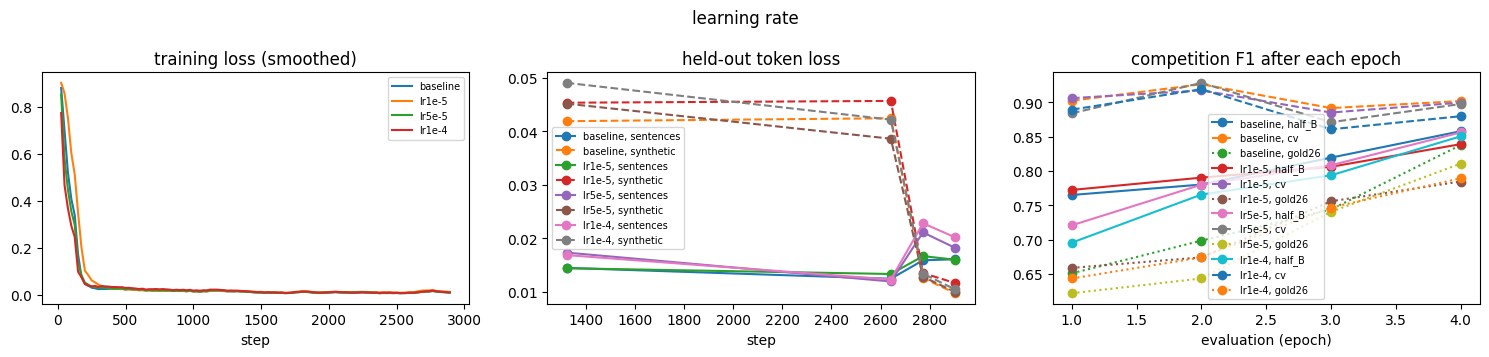

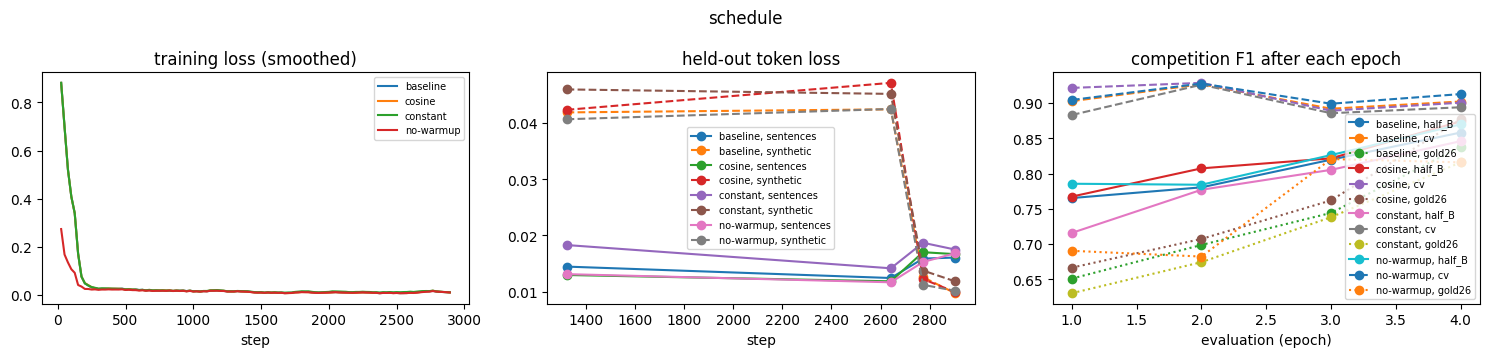

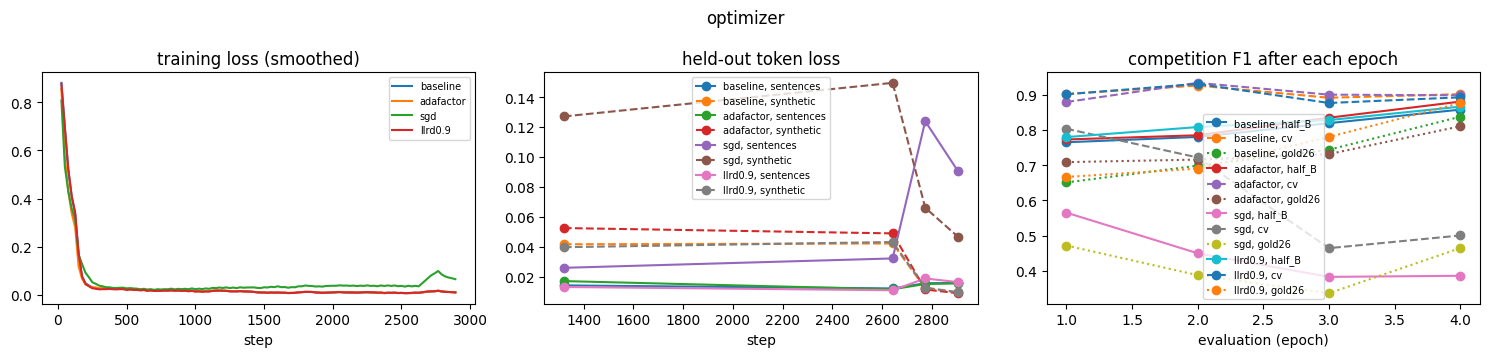

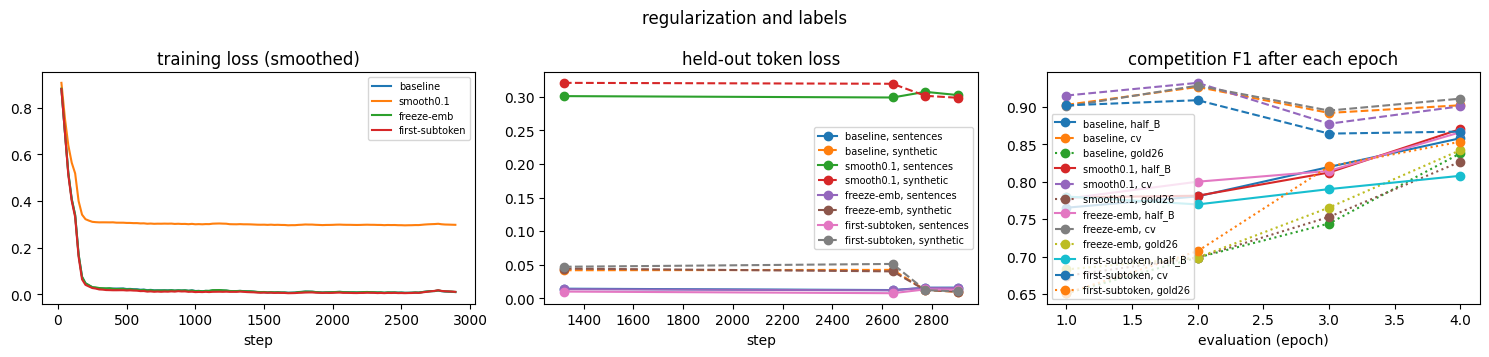

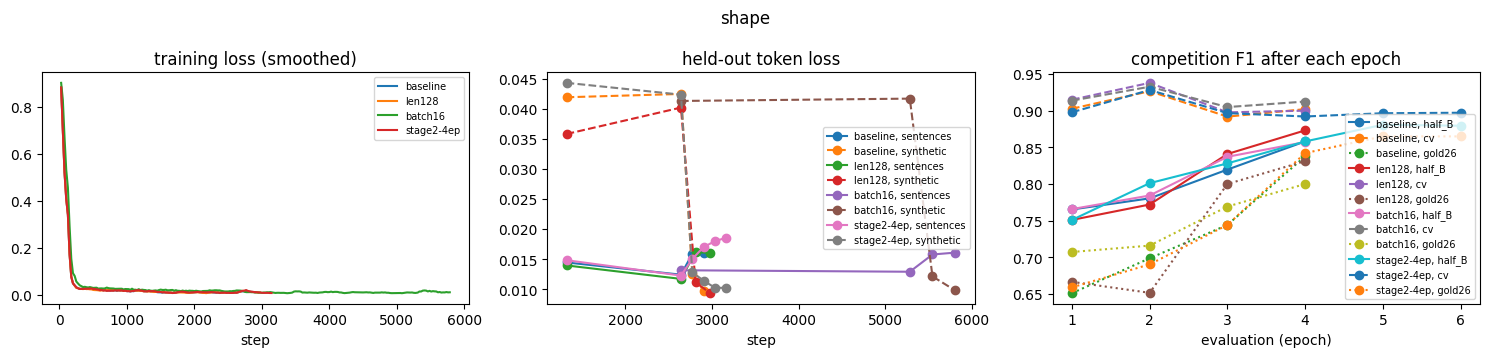

In [20]:
for title, group in GROUPS.items():
    plots.plot_curves({n: runs[n] for n in group if n in runs}, title=title)

Gradient flow: with AdamW the update size doesn't depend on the gradient size, so small gradients in
the lower layers are not a problem by themselves. With SGD they are: the update is the gradient times
the learning rate, so layers with tiny gradients barely move. Compare the two heatmaps.

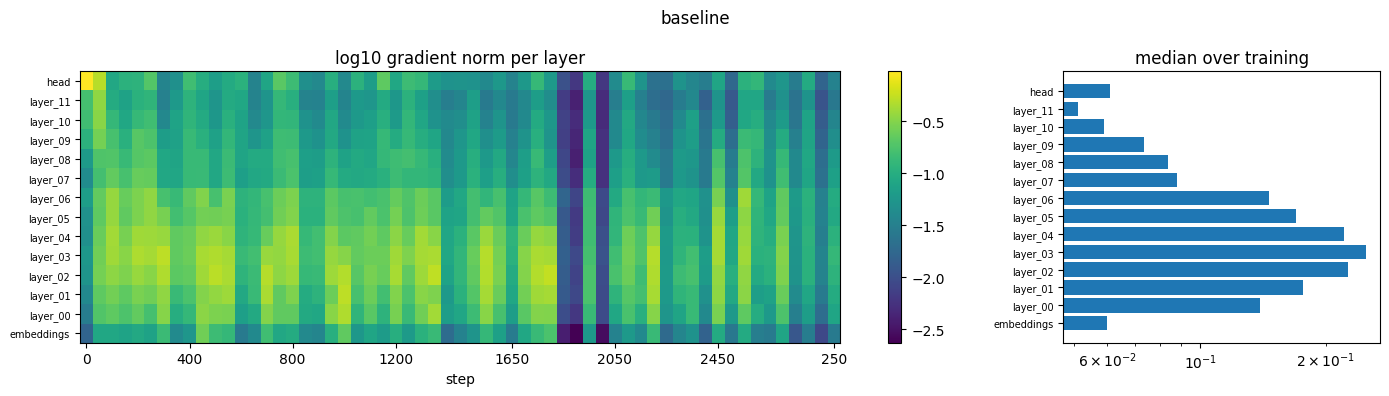

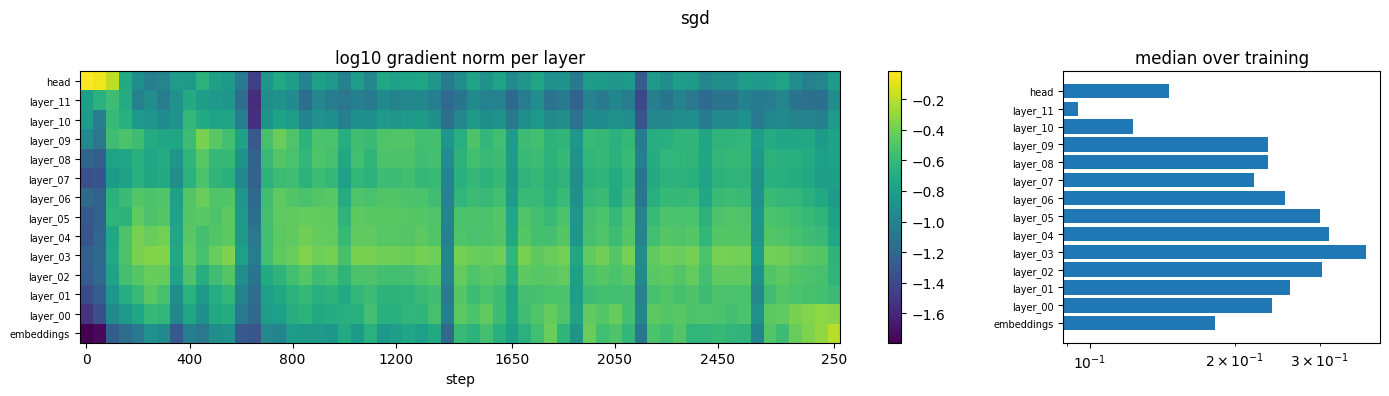

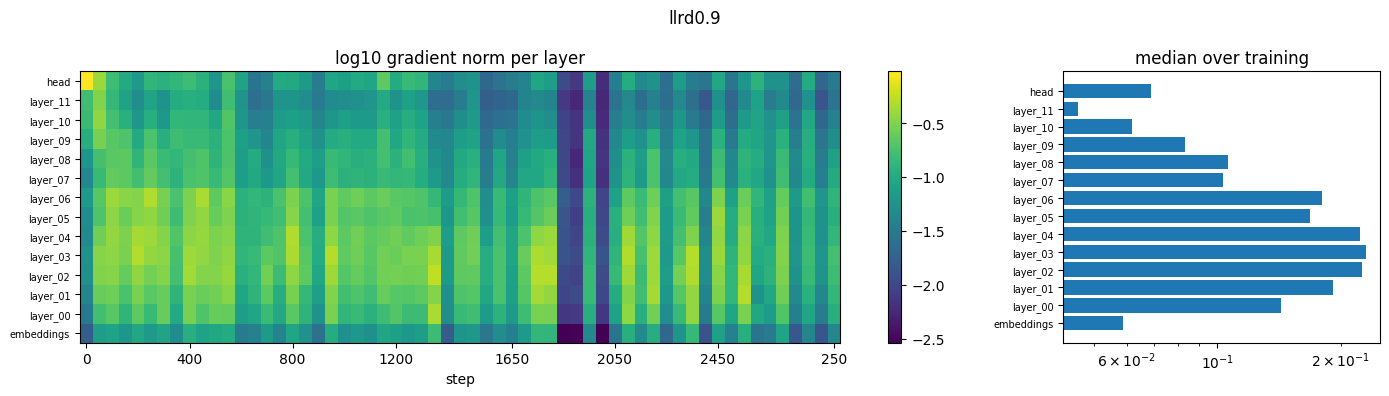

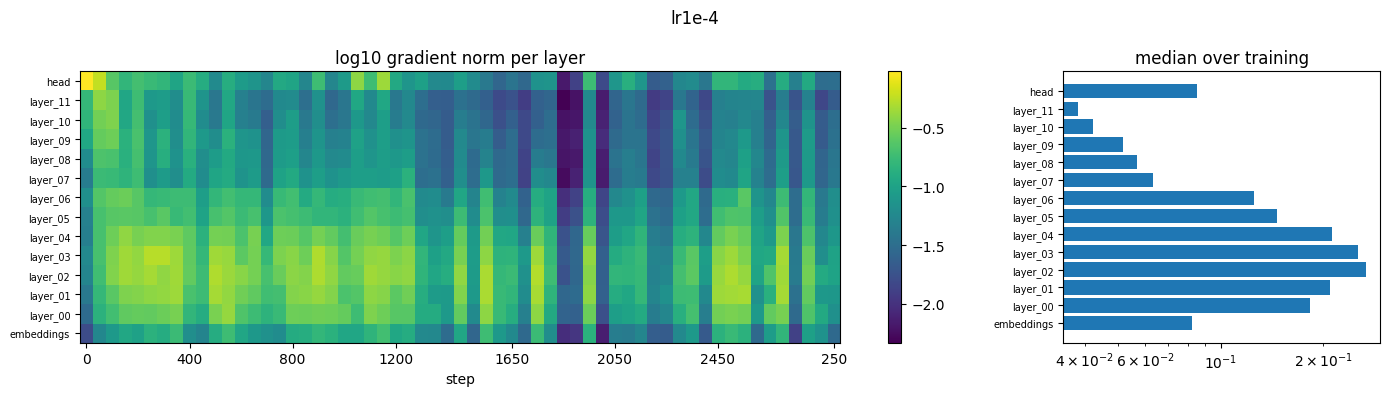

In [21]:
for n in ["baseline", "sgd", "llrd0.9", "lr1e-4"]:
    if n in runs:
        plots.plot_grad_flow(runs[n], title=n)

## Conclusions

All 16 runs finished (about 6.5 h on a T4, fp16, no `nan` losses).

**How big is the noise?** `02-baseline` has exactly the config and seed of `01-two-stage`. It scores
0.858 on `half_B` instead of 0.872, and the two runs disagree on 31 of the 238 posts. Fine-tuning on a
GPU is not bit-for-bit reproducible: the same recipe moves `half_B` by about ±0.015. To get one more
number per run we also look at the mean of `half_A` and `half_B` (477 posts, none used for training), and
we ran a paired bootstrap over posts (5,000 resamples) of each run against the baseline on `half_B`.

| run | cv | half_B | half_A | mean A+B | Δ half_B vs baseline [95% CI] |
| --- | --- | --- | --- | --- | --- |
| baseline | 0.893 | 0.858 | 0.887 | 0.872 | |
| (01-two-stage, same config) | 0.897 | 0.872 | 0.891 | 0.881 | +0.015 [-0.007, +0.036] |
| lr 1e-5 | 0.889 | 0.839 | 0.875 | 0.857 | -0.018 [-0.045, +0.009] |
| lr 5e-5 | 0.888 | 0.856 | 0.885 | 0.871 | -0.002 [-0.029, +0.025] |
| lr 1e-4 | 0.880 | 0.851 | 0.856 | 0.853 | -0.007 [-0.038, +0.022] |
| cosine | 0.894 | 0.874 | 0.872 | 0.873 | +0.016 [-0.003, +0.036] |
| constant | 0.885 | 0.846 | 0.885 | 0.866 | -0.012 [-0.046, +0.021] |
| no warmup | 0.897 | 0.870 | 0.881 | 0.875 | +0.012 [-0.006, +0.029] |
| Adafactor (5e-5) | 0.895 | 0.881 | 0.880 | 0.881 | +0.023 [-0.002, +0.049] |
| SGD (5e-3) | 0.491 | 0.386 | 0.406 | 0.396 | **-0.472** [-0.527, -0.418] |
| LLRD 0.9 (5e-5) | 0.885 | 0.867 | 0.887 | 0.877 | +0.009 [-0.013, +0.031] |
| label smoothing 0.1 | 0.887 | 0.870 | 0.882 | 0.876 | +0.013 [-0.007, +0.033] |
| frozen embeddings | 0.897 | 0.866 | 0.888 | 0.877 | +0.008 [-0.011, +0.029] |
| first sub-token only | 0.853 | 0.808 | 0.837 | 0.823 | **-0.050** [-0.081, -0.019] |
| 128-token windows | 0.895 | 0.873 | 0.887 | 0.883 | +0.015 [-0.008, +0.040] |
| batch 16 | 0.897 | 0.857 | 0.881 | 0.869 | -0.001 [-0.029, +0.025] |
| **stage 2 for 4 epochs** | 0.889 | 0.879 | 0.889 | **0.884** | +0.022 [-0.003, +0.046] |

**Only two settings make a clear difference, and both are worse.**
- **SGD with momentum fails** (0.39 on `half_B`, 0.49 on sentences). Its training loss stays about 3 times
  higher than AdamW's. When stage 2 starts, the loss jumps and the held-out sentence loss goes from 0.03
  to 0.12. Its gradient norms are not small (median 0.1-0.3 in every layer). The problem is that SGD gives
  every parameter the same step size, while gradient sizes differ a lot between layers and between
  frequent and rare tokens. Adam's per-parameter scaling is what makes transformer fine-tuning work. A
  larger SGD learning rate might train further, but it would not fix this.
- **Labeling only the first sub-token** costs 5 points on `half_B` and 4 on sentences. Our decoding
  aggregates the probabilities of all tokens of a word, so training the model on all of them matches how
  it is used. With first-token labels, the other tokens of a place get no training signal, so what the
  model predicts for them is arbitrary, and that breaks the word-level decision.

**Everything else is within the seed noise.** Every other change moves `half_B` by less than 0.025, and
every 95% interval includes 0. Some trends are still worth reporting, because they agree across sets:
- *Learning rate:* 3e-5 is the best of the four. 1e-5 is consistently a bit worse (it underfits in 2+2
  epochs), and 1e-4 drops most on `half_A` (0.856) and on sentences. Too high a learning rate overwrites
  more of the pre-trained knowledge. The heatmap for lr 1e-4 shows larger gradients in the lower layers
  in stage 1, but nothing explodes.
- *Schedule:* any decay to zero (linear, cosine) is better than a constant rate (0.846). Without warmup
  the run is not worse, so with a base model and lr 3e-5 warmup is not needed. It is cheap insurance for
  the large model.
- *Adafactor* has the best `half_B` (0.881) and `synthetic` scores, but it is no better on `half_A`. It is
  a reasonable alternative to AdamW that uses less memory, not a clear improvement.
- *Layer-wise lr decay, label smoothing and frozen embeddings* are all ties. Frozen embeddings save 16% of
  training time (20 instead of 24 min) at no cost, because the 250k-token embedding matrix gets no
  optimizer update.
- *128-token windows* are as good as 256 (0.873, mean A+B 0.883). Most posts are short, and windows
  overlap, so context hardly matters.
- *Batch 16* changes nothing and takes 25% longer.
- *Stage 2 for 4 epochs* has the best mean over both test halves (0.884), the highest recall (26 missed
  places in `half_B` against 36) and the best `gold26` (0.865). The curves show `half_B` still rising after
  epoch 4 and flattening at epoch 6. The cost is a further drop on sentences (0.889). The held-out
  sentence loss rises in every stage-2 epoch: the model trades sentence style for post style, which is
  the trade we want. It adds 6 minutes per run.

**Decision for the model notebooks.** We keep AdamW, lr 3e-5, a linear schedule with 10% warmup, batch
32, 256-token windows and all sub-tokens labeled, and we change one thing: **stage 2 runs for 4 epochs
instead of 2**. It is the only change with the theory behind it (from 01, `half_B` was still rising),
the same direction on every test set and the best mean of the two halves. We don't stack the other small
gains (Adafactor, cosine, 128-token windows). Each one alone is within the noise, and we did not test
whether they add up. A wrong guess would carry into every model notebook.